# TP 3 — Text Mining : analyse des opinions et des sentiments

**Objectif :** analyser les avis clients contenus dans la colonne `comment` et produire automatiquement une nouvelle colonne `sentiment_label` avec trois catégories : `positive`, `negative` et `neutral`.

**Méthode choisie :** analyse lexicale des sentiments avec VADER. Cette méthode analyse directement les textes et ne nécessite pas d'entraînement d'un modèle sur notre jeu de données.

**Données :** fichier CSV exporté depuis Altair AI Studio. Le fichier doit contenir une colonne nommée `comment`.

## 1. Installation des bibliothèques

- **Pandas** : chargement et manipulation du fichier CSV.
- **NLTK** : tokenisation et liste de mots vides (*stop words*).
- **VADER** : calcul du score de sentiment des commentaires.
- **Matplotlib / Seaborn** : visualisation des résultats.

La bibliothèque `vaderSentiment` est utilisée pour appliquer VADER.

In [ ]:
!pip -q install pandas nltk vaderSentiment matplotlib seaborn

## 2. Importation des bibliothèques

In [ ]:
import pandas as pd
import nltk
import re
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Téléchargement des ressources NLTK nécessaires
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Configuration générale des graphiques
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## 3. Chargement du fichier CSV

Exécuter la cellule, choisir le fichier exporté depuis Altair AI Studio, puis vérifier les premières lignes.

Le code tente plusieurs encodages courants afin de faciliter la lecture du fichier.

In [ ]:

# 1. Importer l'outil de chargement de fichiers de Google Colab
from google.colab import files

# 2. Sélectionner le fichier CSV depuis l'ordinateur
uploaded = files.upload()

# 3. Récupérer le nom du fichier importé
file_name = next(iter(uploaded))

# 4. Lire le fichier CSV
# sep=";" indique que les colonnes sont séparées par des points-virgules
try:
    df = pd.read_csv(file_name, sep=";", encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv(file_name, sep=";", encoding="latin-1")

# 5. Afficher les informations du dataset
print("Dimensions du dataset :", df.shape)
print("Colonnes disponibles :", df.columns.tolist())

# Afficher les premières lignes
display(df.head())


Saving resultat_pretraitementA.csv to resultat_pretraitementA.csv
Dimensions du dataset : (100, 4)
Colonnes disponibles : ['comment', 'id', 'product_name', 'price']


,comment,id,product_name,price
0,there are no wheels to move coolerits very hard to place cooler after filling waterhorrible experiencedont go for this,1,"MAHARAJA WHITELINE 65 L Desert Air Cooler (White, Grey, Rambo Grey / AC-303)",7999
1,best cooler i bought 6884,2,"MAHARAJA WHITELINE 65 L Desert Air Cooler (White, Grey, Rambo Grey / AC-303)",7999
2,worst product fan speed very slowlike nothing,3,"MAHARAJA WHITELINE 65 L Desert Air Cooler (White, Grey, Rambo Grey / AC-303)",7999
3,cooler is jabardast but not honeycomb pad,4,"MAHARAJA WHITELINE 65 L Desert Air Cooler (White, Grey, Rambo Grey / AC-303)",7999
4,product is very powerful cooling capacity very good,5,"MAHARAJA WHITELINE 65 L Desert Air Cooler (White, Grey, Rambo Grey / AC-303)",7999


## 4. Vérification et préparation de la colonne `comment`

On vérifie que la colonne attendue existe, qu'elle ne contient pas de valeurs manquantes et qu'elle est bien de type texte.

On conserve le texte d'origine dans `comment`. Une copie `comment_clean` sera utilisée pour les opérations de tokenisation et de suppression des stop words.

In [ ]:
# Vérifier la présence de la colonne comment
if "comment" not in df.columns:
    raise ValueError(
        "La colonne 'comment' est introuvable. "
        "Vérifiez le nom de la colonne dans votre fichier CSV."
    )

# Supprimer les lignes dont le commentaire est manquant
df = df.dropna(subset=["comment"]).copy()

# Convertir les commentaires en chaînes de caractères
df["comment"] = df["comment"].astype(str)

# Supprimer les commentaires vides ou composés uniquement d'espaces
df["comment"] = df["comment"].str.strip()
df = df[df["comment"] != ""].copy()

print("Nombre de commentaires exploitables :", len(df))
display(df[["comment"]].head())

Nombre de commentaires exploitables : 100


,comment
0,there are no wheels to move coolerits very hard to place cooler after filling waterhorrible experiencedont go for this
1,best cooler i bought 6884
2,worst product fan speed very slowlike nothing
3,cooler is jabardast but not honeycomb pad
4,product is very powerful cooling capacity very good


## 5. Prétraitement textuel : normalisation et tokenisation

La tokenisation consiste à découper chaque commentaire en une liste de mots (*tokens*).

On crée une colonne `tokens` pour conserver le résultat de cette opération. Le texte original `comment` reste inchangé.

In [ ]:
def tokenize_comment(text):
    # Uniformiser la casse pour cette représentation textuelle
    text = text.lower()

    # Tokeniser le texte en mots
    tokens = word_tokenize(text)

    # Garder les mots et les nombres, sans les éléments de ponctuation seuls
    tokens = [token for token in tokens if re.search(r"[a-z0-9]", token)]

    return tokens

df["tokens"] = df["comment"].apply(tokenize_comment)

display(df[["comment", "tokens"]].head())

,comment,tokens
0,there are no wheels to move coolerits very hard to place cooler after filling waterhorrible experiencedont go for this,"[there, are, no, wheels, to, move, coolerits, very, hard, to, place, cooler, after, filling, waterhorrible, experien..."
1,best cooler i bought 6884,"[best, cooler, i, bought, 6884]"
2,worst product fan speed very slowlike nothing,"[worst, product, fan, speed, very, slowlike, nothing]"
3,cooler is jabardast but not honeycomb pad,"[cooler, is, jabardast, but, not, honeycomb, pad]"
4,product is very powerful cooling capacity very good,"[product, is, very, powerful, cooling, capacity, very, good]"


## 6. Suppression des stop words

Les *stop words* sont des mots très fréquents qui apportent souvent peu d'information pour certaines analyses textuelles.

On utilise la liste anglaise de NLTK, puisque les avis sont rédigés en anglais.

**Précaution :** on conserve explicitement les négations (`no`, `not`, `nor`, `never`, etc.), car elles peuvent inverser le sens d'un commentaire. On crée une colonne `tokens_clean` sans modifier `comment`.

In [ ]:
english_stop_words = set(stopwords.words("english"))

# Négations et formes contractées à préserver
negations_to_keep = {
    "no", "not", "nor", "never", "neither",
    "n't", "cannot", "without"
}

english_stop_words = english_stop_words - negations_to_keep

def remove_stop_words(tokens):
    return [
        token for token in tokens
        if token not in english_stop_words
    ]

df["tokens_clean"] = df["tokens"].apply(remove_stop_words)

# Reconstituer les tokens filtrés en une chaîne de caractères
df["comment_clean"] = df["tokens_clean"].apply(lambda tokens: " ".join(tokens))

display(df[["comment", "tokens", "tokens_clean", "comment_clean"]].head())

,comment,tokens,tokens_clean,comment_clean
0,there are no wheels to move coolerits very hard to place cooler after filling waterhorrible experiencedont go for this,"[there, are, no, wheels, to, move, coolerits, very, hard, to, place, cooler, after, filling, waterhorrible, experien...","[no, wheels, move, coolerits, hard, place, cooler, filling, waterhorrible, experiencedont, go]",no wheels move coolerits hard place cooler filling waterhorrible experiencedont go
1,best cooler i bought 6884,"[best, cooler, i, bought, 6884]","[best, cooler, bought, 6884]",best cooler bought 6884
2,worst product fan speed very slowlike nothing,"[worst, product, fan, speed, very, slowlike, nothing]","[worst, product, fan, speed, slowlike, nothing]",worst product fan speed slowlike nothing
3,cooler is jabardast but not honeycomb pad,"[cooler, is, jabardast, but, not, honeycomb, pad]","[cooler, jabardast, not, honeycomb, pad]",cooler jabardast not honeycomb pad
4,product is very powerful cooling capacity very good,"[product, is, very, powerful, cooling, capacity, very, good]","[product, powerful, cooling, capacity, good]",product powerful cooling capacity good


## 7. Analyse des sentiments avec VADER

VADER (*Valence Aware Dictionary and sEntiment Reasoner*) est un outil d'analyse de sentiments particulièrement adapté aux textes courts en anglais.

Il calcule notamment un score `compound`, compris entre -1 et +1 :
- score supérieur ou égal à **0,05** : sentiment positif ;
- score inférieur ou égal à **-0,05** : sentiment négatif ;
- score compris entre **-0,05 et 0,05** : sentiment neutre.

**Important :** pour l'analyse VADER, on utilise la colonne `comment` originale et non `comment_clean`. VADER exploite notamment la ponctuation, les majuscules et les négations ; retirer ces éléments ou supprimer des mots peut dégrader l'analyse. Les colonnes tokenisées et nettoyées sont conservées pour montrer les étapes de prétraitement.

In [ ]:
analyzer = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    # Calculer les scores VADER sur le commentaire original
    return analyzer.polarity_scores(text)

# Récupérer les scores sous forme de dictionnaire
sentiment_scores = df["comment"].apply(analyze_sentiment)

# Ajouter les scores au dataset
df["vader_negative"] = sentiment_scores.apply(lambda scores: scores["neg"])
df["vader_neutral"] = sentiment_scores.apply(lambda scores: scores["neu"])
df["vader_positive"] = sentiment_scores.apply(lambda scores: scores["pos"])
df["vader_compound"] = sentiment_scores.apply(lambda scores: scores["compound"])

display(df[[
    "comment", "vader_negative", "vader_neutral",
    "vader_positive", "vader_compound"
]].head())

,comment,vader_negative,vader_neutral,vader_positive,vader_compound
0,there are no wheels to move coolerits very hard to place cooler after filling waterhorrible experiencedont go for this,0.186,0.814,0.000,-0.4391
1,best cooler i bought 6884,0.000,0.488,0.512,0.6369
2,worst product fan speed very slowlike nothing,0.360,0.439,0.202,-0.4215
3,cooler is jabardast but not honeycomb pad,0.000,1.000,0.000,0.0000
4,product is very powerful cooling capacity very good,0.000,0.488,0.512,0.7420


## 8. Création de la colonne `sentiment_label`

On transforme le score `compound` en une catégorie : `positive`, `negative` ou `neutral`.

Les seuils utilisés sont ceux couramment proposés pour le score compound de VADER.

In [ ]:
def classify_sentiment(compound_score):
    if compound_score >= 0.05:
        return "positive"
    elif compound_score <= -0.05:
        return "negative"
    else:
        return "neutral"

df["sentiment_label"] = df["vader_compound"].apply(classify_sentiment)

display(df[["comment", "vader_compound", "sentiment_label"]].head(10))

,comment,vader_compound,sentiment_label
0,there are no wheels to move coolerits very hard to place cooler after filling waterhorrible experiencedont go for this,-0.4391,negative
1,best cooler i bought 6884,0.6369,positive
2,worst product fan speed very slowlike nothing,-0.4215,negative
3,cooler is jabardast but not honeycomb pad,0.0000,neutral
4,product is very powerful cooling capacity very good,0.7420,positive
5,air throw is very good it makes room very cool in just half an hour full tank capacity is 65 litres which stays up t...,0.7587,positive
6,on time delivery received exact productthank u flipkart,0.0000,neutral
7,dont buy this product within 15 year wind blade was broken and noise issue wind blow very low its better to go othe...,-0.3246,negative
8,capacity of cooler is not 65lt water indicator not work,0.0000,neutral
9,not good water leaking after one month return period,-0.3412,negative


## 9. Tableau récapitulatif des sentiments

On calcule le nombre et le pourcentage de commentaires appartenant à chaque catégorie.

In [ ]:
sentiment_summary = (
    df["sentiment_label"]
    .value_counts()
    .reindex(["positive", "negative", "neutral"], fill_value=0)
    .rename_axis("sentiment_label")
    .reset_index(name="nombre")
)

sentiment_summary["pourcentage"] = (
    sentiment_summary["nombre"] / len(df) * 100
).round(2)

display(sentiment_summary)

,sentiment_label,nombre,pourcentage
0,positive,37,37.0
1,negative,38,38.0
2,neutral,25,25.0


## 10. Visualisation 1 — Nombre de commentaires par sentiment

Ce diagramme en barres compare le nombre d'avis positifs, négatifs et neutres.

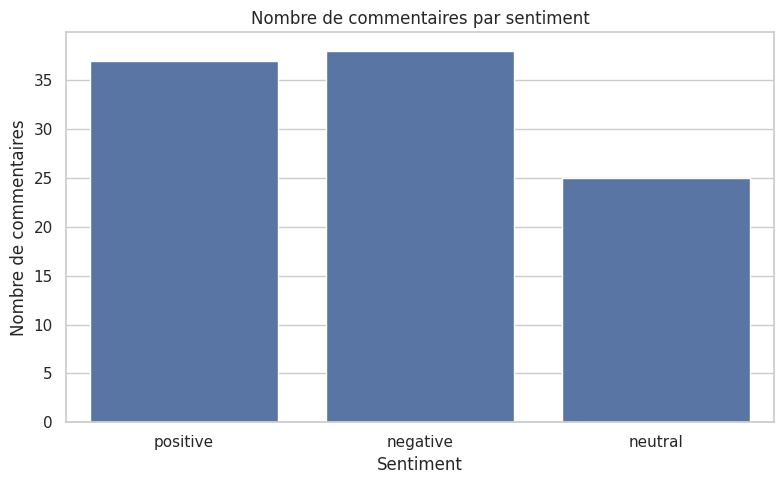

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=sentiment_summary,
    x="sentiment_label",
    y="nombre"
)
plt.title("Nombre de commentaires par sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Nombre de commentaires")
plt.tight_layout()
plt.show()

## 11. Visualisation 2 — Répartition en pourcentage

Ce diagramme circulaire montre la proportion de chaque catégorie dans l'ensemble des commentaires.

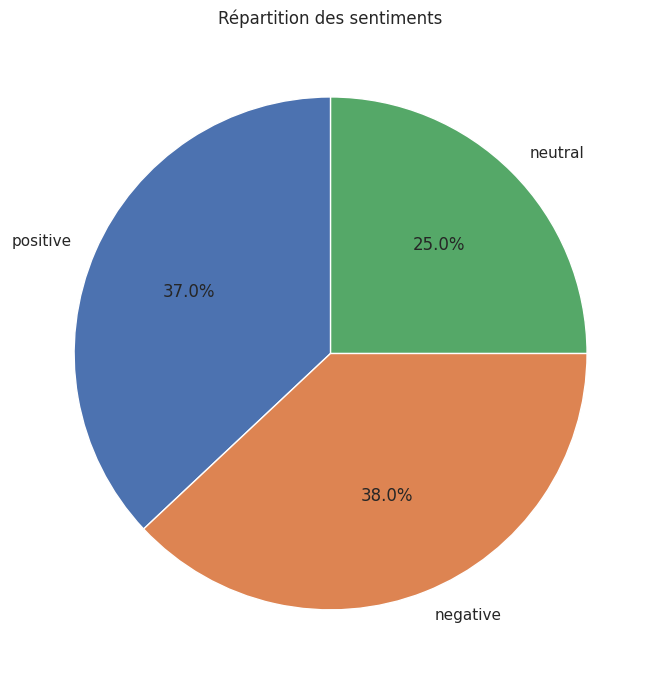

In [ ]:
plt.figure(figsize=(7, 7))
plt.pie(
    sentiment_summary["nombre"],
    labels=sentiment_summary["sentiment_label"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Répartition des sentiments")
plt.tight_layout()
plt.show()

## 12. Visualisation 3 — Distribution des scores VADER

L'histogramme permet d'observer comment les scores `compound` sont répartis entre les valeurs négatives et positives.

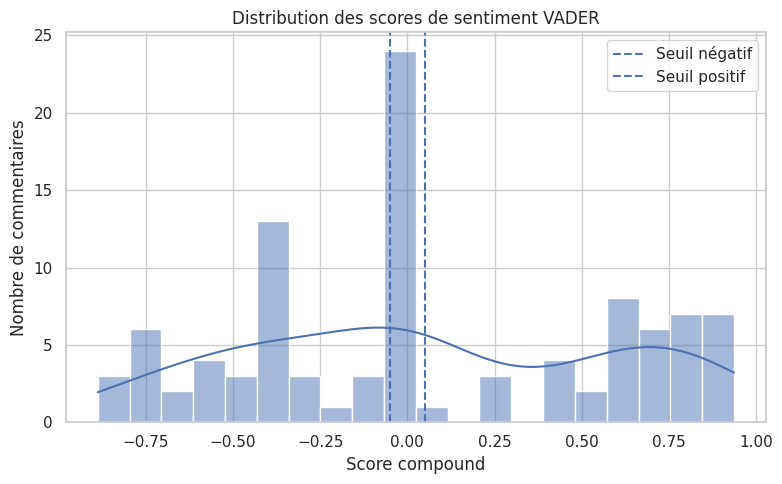

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="vader_compound",
    bins=20,
    kde=True
)
plt.axvline(-0.05, linestyle="--", label="Seuil négatif")
plt.axvline(0.05, linestyle="--", label="Seuil positif")
plt.title("Distribution des scores de sentiment VADER")
plt.xlabel("Score compound")
plt.ylabel("Nombre de commentaires")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Consulter les commentaires classés

Ce tableau permet de vérifier quelques résultats et de rapprocher chaque commentaire de son score et de sa catégorie prédite.

In [ ]:
result_columns = [
    "comment",
    "vader_compound",
    "sentiment_label"
]

display(
    df[result_columns]
    .sort_values("vader_compound")
    .head(10)
)

display(
    df[result_columns]
    .sort_values("vader_compound", ascending=False)
    .head(10)
)

,comment,vader_compound,sentiment_label
70,not upto the reviews build up level too bulky quite noisy lack of wheel is biggest disadvantage buy at your own ri...,-0.8878,negative
27,not working properly not able return also so for me it is verry bad product it should be returnable product cause ...,-0.8070,negative
81,item is vry bad i hate flipcart item this watch is,-0.8020,negative
96,cooler is averagefan speed is high which cause a little bit noise but youll get use to itcooling is ok depend on wea...,-0.7684,negative
91,very bad product its water tank is not sufficient for a day tank empty in 4 hours and not open easily for cleaning,-0.7670,negative
86,not effective cooling fan area of effect is also very narrow not ideal returned it,-0.7619,negative
46,very poor product and heavy smell through out the room received damaged,-0.7425,negative
54,not satisfied with the cooling very bad cooling,-0.7290,negative
76,nice product but weighty is very heavy no wheels provided so that is is very difficult to move from one place to ano...,-0.7190,negative
45,this product does not cool as much as it was written in the advertisement i am not so happy with this product,-0.6937,negative


,comment,vader_compound,sentiment_label
15,not go for negative comment its size perfect for room i also used for two three days perfect working not a weak moto...,0.9367,positive
39,nice product thanks to flipkart for early delivery special thanks to delivery boy for gentle behaviour,0.9217,positive
53,superb cooler it cools room within 5 minute amazing cooler amazing price,0.9136,positive
44,excellent team safe hygiene deliveryproduct working really great,0.8999,positive
68,fantastic product great cool,0.8750,positive
13,cooler is really very good but use any cooler ventilation os a must without ventilation no cooler will work especial...,0.8735,positive
73,good delivery value for money best cooler ever,0.8591,positive
18,great deal perfect cooling,0.8316,positive
33,great qualitycooling is nice,0.7845,positive
17,amazing product it works wonders in 45c and always go for wood woolen pads as theyre better than honeycomb,0.7717,positive


## 14. Exportation du résultat final

Le fichier exporté contient le commentaire d'origine, les colonnes de prétraitement, les scores VADER et la nouvelle colonne `sentiment_label`.

In [ ]:
output_file = "resultats_analyse_sentiments.csv"

df.to_csv(output_file, index=False, encoding="utf-8-sig")

print("Fichier créé :", output_file)
files.download(output_file)

Fichier créé : resultats_analyse_sentiments.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Conclusion

Cette analyse a permis de préparer les commentaires textuels, de calculer leur polarité avec VADER et de les classer en trois catégories : positive, negative et neutral. Les résultats ont ensuite été résumés dans un tableau et représentés graphiquement.

**Limite à signaler :** VADER repose sur un lexique et des règles linguistiques. Il peut mal interpréter certains contextes, le sarcasme, les formulations complexes ou les avis contenant des expressions spécifiques à un produit. Les résultats sont donc des estimations automatiques et non des vérités absolues.

**Remarque méthodologique :** les opérations de tokenisation et de suppression des stop words sont présentées dans les colonnes `tokens` et `tokens_clean`. Le score VADER est volontairement calculé à partir du commentaire original afin de préserver les indices linguistiques utiles à l'analyse du sentiment.